<a href="https://colab.research.google.com/github/edgarcolmenero/OpsDesk-Project/blob/main/OpsDesk_Warehouse_IT_Incident_%26_Network_Diagnostics_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OPSDESK | Warehouse IT Simulation
Registered devices: 10


,device_id,name,type,zone,ip
0,WS-101,Packing workstation,workstation,Packing,10.20.1.21
1,WS-102,Receiving workstation,workstation,Receiving,10.20.1.22
2,WS-103,Shipping workstation,workstation,Shipping,10.20.1.23
3,SCN-201,Handheld scanner,scanner,Receiving,10.20.1.24
4,SCN-202,Picking scanner,scanner,Picking,10.20.1.25
5,SCN-203,Packing scanner,scanner,Packing,10.20.1.26
6,PRN-301,Label printer,printer,Shipping,10.20.1.27
7,PRN-302,Receiving printer,printer,Receiving,10.20.1.28
8,PRN-303,Packing printer,printer,Packing,10.20.1.29
9,AP-401,Wireless access point,access_point,Picking,10.20.1.30



INCIDENT RECORDS


,ticket,device,zone,symptom,likely_cause,priority,status,recommended_action,resolution_notes
0,INC-0001,WS-101,Packing,Station will not power on,Power failure,P2,Resolved (simulated),"Check power cable, supply, or charging dock.",Checked and reconnected power supply; boot tes...
1,INC-0002,WS-102,Receiving,Wired network disconnected,Ethernet link down,P2,Open,"Check cable, network card, and switch port.",
2,INC-0003,WS-103,Shipping,Workstation has invalid IP,DHCP assignment issue,P2,Open,Check DHCP service and renew lease.,
3,INC-0004,WS-101,Packing,Hostname lookup fails,DNS lookup failure,P2,Open,Check resolver settings and DNS health.,
4,INC-0005,WS-102,Receiving,Warehouse app will not load,Warehouse app unavailable,P1,Open,Check service health; escalate to app team.,
5,INC-0006,SCN-201,Receiving,Scanner shuts down,Low scanner battery,P3,Resolved (simulated),Charge or replace approved battery.,Recharged scanner and verified barcode scan.
6,INC-0007,SCN-202,Picking,Scanner frequently disconnects,Weak Wi-Fi signal,P2,Open,Check access-point coverage and roaming.,
7,INC-0008,SCN-203,Packing,Barcodes are not being entered,Scanner pairing issue,P3,Open,Re-pair and test barcode input.,
8,INC-0009,PRN-301,Shipping,Printer jam warning,Printer paper jam,P2,Open,Clear jam safely and test print.,
9,INC-0010,PRN-302,Receiving,Labels no longer printing,Out of printer labels,P2,Open,Reload label stock and test print.,



Ticket status counts:
status
Open                    11
Resolved (simulated)     2
Monitoring               1
Name: count, dtype: int64

Priority counts:
priority
P1    3
P2    8
P3    2
P4    1
Name: count, dtype: int64


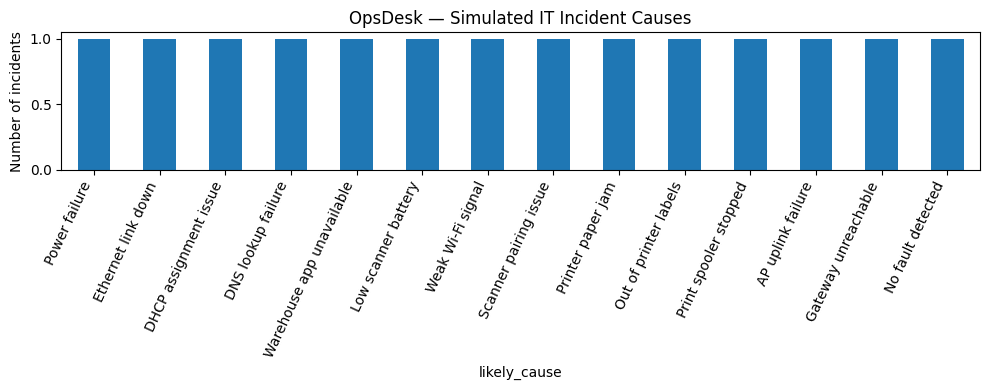


Saved incident_tickets.csv and device_inventory.csv in /content/OpsDesk

CUSTOM TEST: WS-101 | Injected fault: dns_failure
Likely cause: DNS lookup failure | Priority: P2
Recommended action: Check resolver settings and DNS health.


In [1]:

# OpsDesk | Warehouse IT Incident & Network Diagnostics Simulator
# Paste into ONE Google Colab code cell and run.
# All devices and connectivity tests are simulated.

import copy
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# STEP 1 — Warehouse device inventory

assets = [
    ("WS-101", "Packing workstation", "workstation", "Packing"),
    ("WS-102", "Receiving workstation", "workstation", "Receiving"),
    ("WS-103", "Shipping workstation", "workstation", "Shipping"),
    ("SCN-201", "Handheld scanner", "scanner", "Receiving"),
    ("SCN-202", "Picking scanner", "scanner", "Picking"),
    ("SCN-203", "Packing scanner", "scanner", "Packing"),
    ("PRN-301", "Label printer", "printer", "Shipping"),
    ("PRN-302", "Receiving printer", "printer", "Receiving"),
    ("PRN-303", "Packing printer", "printer", "Packing"),
    ("AP-401", "Wireless access point", "access_point", "Picking"),
]

inventory = {}

for i, (device_id, name, kind, zone) in enumerate(assets, start=21):
    inventory[device_id] = dict(
        device_id=device_id,
        name=name,
        type=kind,
        zone=zone,
        power=True,
        ethernet=True,
        ip=f"10.20.1.{i}",
        gateway=True,
        dns=True,
        wms=True,
        battery=90,
        wifi=-55,
        paired=True,
        jam=False,
        labels=100,
        spooler=True,
        uplink=True,
    )

print("OPSDESK | Warehouse IT Simulation")
print("Registered devices:", len(inventory))

display(
    pd.DataFrame(inventory.values())[
        ["device_id", "name", "type", "zone", "ip"]
    ]
)

# STEP 2 — Simulated equipment and connectivity faults

faults = {
    "power_loss": {"power": False},
    "cable_unplugged": {"ethernet": False},
    "dhcp_failure": {"ip": "169.254.12.9"},
    "gateway_down": {"gateway": False},
    "dns_failure": {"dns": False},
    "wms_down": {"wms": False},
    "battery_low": {"battery": 4},
    "weak_wifi": {"wifi": -88},
    "scanner_unpaired": {"paired": False},
    "printer_jam": {"jam": True},
    "out_of_labels": {"labels": 0},
    "spooler_stopped": {"spooler": False},
    "ap_uplink_down": {"uplink": False},
    "healthy": {},
}

def simulate(device_id, fault):
    if device_id not in inventory or fault not in faults:
        raise ValueError("Choose a valid device ID and fault name.")

    state = copy.deepcopy(inventory[device_id])
    state.update(faults[fault])
    return state

# STEP 3 — Rule-based diagnostic engine

def diagnose(s):
    kind = s["type"]

    if not s["power"]:
        return (
            "Power failure", "P2",
            "Check power cable, supply, or charging dock."
        )

    if kind == "access_point" and not s["uplink"]:
        return (
            "AP uplink failure", "P1",
            "Check switch port and upstream network."
        )

    if kind == "scanner" and s["battery"] <= 10:
        return (
            "Low scanner battery", "P3",
            "Charge or replace approved battery."
        )

    if kind == "scanner" and s["wifi"] <= -80:
        return (
            "Weak Wi-Fi signal", "P2",
            "Check access-point coverage and roaming."
        )

    if kind == "scanner" and not s["paired"]:
        return (
            "Scanner pairing issue", "P3",
            "Re-pair and test barcode input."
        )

    if kind == "printer" and s["jam"]:
        return (
            "Printer paper jam", "P2",
            "Clear jam safely and test print."
        )

    if kind == "printer" and s["labels"] == 0:
        return (
            "Out of printer labels", "P2",
            "Reload label stock and test print."
        )

    if kind == "printer" and not s["spooler"]:
        return (
            "Print spooler stopped", "P2",
            "Check queue and approved spooler restart."
        )

    if kind in ("workstation", "printer") and not s["ethernet"]:
        return (
            "Ethernet link down", "P2",
            "Check cable, network card, and switch port."
        )

    if s["ip"].startswith("169.254."):
        return (
            "DHCP assignment issue", "P2",
            "Check DHCP service and renew lease."
        )

    if not s["gateway"]:
        return (
            "Gateway unreachable", "P1",
            "Check VLAN, gateway, and network incident status."
        )

    if not s["dns"]:
        return (
            "DNS lookup failure", "P2",
            "Check resolver settings and DNS health."
        )

    if kind == "workstation" and not s["wms"]:
        return (
            "Warehouse app unavailable", "P1",
            "Check service health; escalate to app team."
        )

    return (
        "No fault detected", "P4",
        "Monitor and collect more symptom details."
    )

# STEP 4 — Generate simulated incident tickets

scenarios = [
    ("WS-101", "power_loss", "Station will not power on"),
    ("WS-102", "cable_unplugged", "Wired network disconnected"),
    ("WS-103", "dhcp_failure", "Workstation has invalid IP"),
    ("WS-101", "dns_failure", "Hostname lookup fails"),
    ("WS-102", "wms_down", "Warehouse app will not load"),
    ("SCN-201", "battery_low", "Scanner shuts down"),
    ("SCN-202", "weak_wifi", "Scanner frequently disconnects"),
    ("SCN-203", "scanner_unpaired", "Barcodes are not being entered"),
    ("PRN-301", "printer_jam", "Printer jam warning"),
    ("PRN-302", "out_of_labels", "Labels no longer printing"),
    ("PRN-303", "spooler_stopped", "Jobs stuck in print queue"),
    ("AP-401", "ap_uplink_down", "Picking-area Wi-Fi unavailable"),
    ("WS-103", "gateway_down", "Cannot reach default gateway"),
    ("WS-103", "healthy", "Follow-up connectivity check"),
]

records = []

for i, (device_id, fault, symptom) in enumerate(scenarios, start=1):
    state = simulate(device_id, fault)
    cause, priority, next_step = diagnose(state)

    records.append({
        "ticket": f"INC-{i:04d}",
        "device": device_id,
        "zone": state["zone"],
        "symptom": symptom,
        "likely_cause": cause,
        "priority": priority,
        "status": "Monitoring" if cause == "No fault detected" else "Open",
        "recommended_action": next_step,
        "resolution_notes": "",
    })

# STEP 5 — Document simulated resolutions

records[0]["status"] = "Resolved (simulated)"
records[0]["resolution_notes"] = (
    "Checked and reconnected power supply; boot test passed."
)

records[5]["status"] = "Resolved (simulated)"
records[5]["resolution_notes"] = (
    "Recharged scanner and verified barcode scan."
)

tickets = pd.DataFrame(records)

print("\nINCIDENT RECORDS")
display(tickets)

print("\nTicket status counts:")
print(tickets["status"].value_counts())

print("\nPriority counts:")
print(tickets["priority"].value_counts().sort_index())

# STEP 6 — Incident analytics dashboard

plt.figure(figsize=(10, 4))

tickets["likely_cause"].value_counts().plot(kind="bar")

plt.title("OpsDesk — Simulated IT Incident Causes")
plt.ylabel("Number of incidents")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

# Export incident tickets and device inventory

out = (
    Path("/content/OpsDesk")
    if Path("/content").exists()
    else Path("OpsDesk_outputs")
)

out.mkdir(exist_ok=True)

tickets.to_csv(out / "incident_tickets.csv", index=False)

pd.DataFrame(inventory.values()).to_csv(
    out / "device_inventory.csv",
    index=False
)

print(f"\nSaved incident_tickets.csv and device_inventory.csv in {out}")

# STEP 7 — Your own troubleshooting practice
# Edit these two values to test another scenario.

MY_DEVICE = "WS-101"
MY_FAULT = "dns_failure"

result = diagnose(simulate(MY_DEVICE, MY_FAULT))

print(f"\nCUSTOM TEST: {MY_DEVICE} | Injected fault: {MY_FAULT}")
print("Likely cause:", result[0], "| Priority:", result[1])
print("Recommended action:", result[2])
